In [1]:
from __future__ import annotations

from dataclasses import dataclass
from pathlib import Path
from typing import Any, Literal

import math
import string

import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages

In [2]:
@dataclass
class QboPlotParameter:
    main_title: str
    test_yrs: str
    ref_yrs: str
    case_id: str = ""
    ref_name: str = ""

    # variable metadata for correct labeling (U vs T)
    var_label: str = "U"                 # e.g. "U" or "T"
    var_units: str = r"m s$^{-1}$"       # e.g. r"m s$^{-1}$" or "K"

    # what to plot by default
    default_field: Literal["qbo", "qbo_anom"] = "qbo"

    # how to compute anomalies when field="qbo_anom"
    # - "own_clim": remove each dataset's own month-of-year climatology
    # - "ref_clim": remove the reference month-of-year climatology (recommended for cross-exp comparability)
    # - "first_month": subtract the first-month profile (keeps initial structure comparable)
    default_anom_mode: Literal["own_clim", "ref_clim", "first_month"] = "ref_clim"


# -------------------------
# Minimal diagnostics container loaded from NetCDF
# -------------------------
@dataclass
class SavedQboDiag:
    name: str
    qbo: xr.DataArray          # (time, plev) raw (as saved)
    amplitude: xr.DataArray    # (plev,)
    amp_method: str


class QboPlotter:
    """
    Plot QBO-like diagnostics (works for wind U or temperature T) from saved NetCDFs.

    Assumptions:
      - test and reference have consistent monthly time coordinate (YYYYMM match)
      - test and reference have consistent pressure coordinate name and values (plev)
      - therefore: NO time alignment, NO pressure interpolation

    Notes on anomalies:
      - You said you saved RAW qbo (e.g., T or U). That’s fine.
      - This plotter can compute anomalies on-the-fly (qbo_anom) without changing saved files.
      - For inter-experiment comparability, "ref_clim" anomalies are usually the cleanest choice.
    """

    def __init__(self, parameter: QboPlotParameter):
        self.parameter = parameter

    # -------------------------
    # Load saved diagnostics
    # -------------------------
    def load_diagnostics(
        self,
        in_path: str | Path,
        name: str | None = None,
        amplitude_method: Literal["p2p", "rms", "rms_detrend"] = "rms",
    ) -> SavedQboDiag:
        in_path = Path(in_path)
        ds = xr.open_dataset(in_path)

        exp_name = name or ds.attrs.get("name", in_path.stem)

        # Always load RAW qbo from file (as you saved it)
        if "qbo" not in ds:
            raise KeyError(f"{in_path}: missing variable 'qbo' (available={list(ds.data_vars)})")

        amp_var_map = {
            "p2p": "amp_p2p",
            "rms": "amp_rms",
            "rms_detrend": "amp_rms_detrend",
        }
        amp_var = amp_var_map[amplitude_method]
        if amp_var not in ds:
            raise KeyError(f"{in_path}: missing amplitude var '{amp_var}'. available={list(ds.data_vars)}")

        qbo = ds["qbo"]
        if qbo.ndim != 2:
            raise ValueError(
                f"{in_path}: qbo must be 2D (time,plev). got dims={qbo.dims} shape={qbo.shape}"
            )

        amp = ds[amp_var].rename("amplitude").squeeze()
        if amp.ndim != 1:
            raise ValueError(
                f"{in_path}: amplitude must be 1D. got dims={amp.dims} shape={amp.shape}"
            )

        return SavedQboDiag(name=exp_name, qbo=qbo, amplitude=amp, amp_method=amplitude_method)

    # -------------------------
    # File helpers
    # -------------------------
    @staticmethod
    def _diag_path(qbo_dir: Path, exp: str, tag: str, period: str) -> Path:
        # tag is part of filename (ua / ta)
        return qbo_dir / f"qbo_{exp}_{tag}_{period}.nc"

    def _load_reference(
        self,
        qbo_dir: Path,
        period: str,
        ref_exp: str,
        tag: str,
        amplitude_method: Literal["p2p", "rms", "rms_detrend"],
    ) -> SavedQboDiag:
        ref_file = self._diag_path(qbo_dir, ref_exp, tag, period)
        if not ref_file.is_file():
            raise FileNotFoundError(f"Reference file not found: {ref_file}")
        return self.load_diagnostics(ref_file, name=ref_exp, amplitude_method=amplitude_method)

    @staticmethod
    def _safe_iter_exps(
        qbo_dir: Path,
        period: str,
        exp_list: list[str],
        tag: str,
        skip_bad: bool,
    ) -> list[tuple[str, Path]]:
        out: list[tuple[str, Path]] = []
        for exp in exp_list:
            f = QboPlotter._diag_path(qbo_dir, exp, tag, period)
            if f.is_file():
                out.append((exp, f))
            else:
                msg = f"Missing diagnostics: {f}"
                if skip_bad:
                    print(f"WARNING: {msg} (skipped)")
                else:
                    raise FileNotFoundError(msg)
        return out

    # -------------------------
    # Coord checks
    # -------------------------
    @staticmethod
    def _yyyymm_from_time(tvals) -> np.ndarray:
        out = np.empty(len(tvals), dtype=int)
        for i, t in enumerate(tvals):
            if hasattr(t, "year") and hasattr(t, "month"):  # cftime/datetime-like
                out[i] = int(t.year) * 100 + int(t.month)
            else:  # numpy datetime64
                s = np.datetime_as_string(t, unit="M")  # "YYYY-MM"
                out[i] = int(s[:4]) * 100 + int(s[5:7])
        return out

    @staticmethod
    def _assert_same_time_and_plev(
        test_qbo: xr.DataArray, ref_qbo: xr.DataArray, debug: bool = False
    ):
        tdim_t, pdim_t = test_qbo.dims
        tdim_r, pdim_r = ref_qbo.dims

        if test_qbo.sizes[tdim_t] != ref_qbo.sizes[tdim_r]:
            raise ValueError(
                f"time length mismatch: test={test_qbo.sizes[tdim_t]} ref={ref_qbo.sizes[tdim_r]}"
            )

        t_test = test_qbo[tdim_t].values
        t_ref = ref_qbo[tdim_r].values
        m_test = QboPlotter._yyyymm_from_time(t_test)
        m_ref = QboPlotter._yyyymm_from_time(t_ref)

        if debug:
            print("test YYYYMM:", m_test)
            print("ref  YYYYMM:", m_ref)

        if not np.array_equal(m_test, m_ref):
            bad = np.where(m_test != m_ref)[0]
            i0 = int(bad[0]) if bad.size else -1
            raise ValueError(
                "time coordinate mismatch in monthly labels (YYYYMM).\n"
                f"first mismatch at index {i0}: test={m_test[i0]} ref={m_ref[i0]}"
            )

        if pdim_t != pdim_r:
            raise ValueError(f"pressure dim mismatch: test={pdim_t} ref={pdim_r}")

        if pdim_t not in test_qbo.coords or pdim_r not in ref_qbo.coords:
            raise ValueError("missing pressure coordinate on qbo arrays")

        p_test = np.asarray(test_qbo[pdim_t].values, dtype=float)
        p_ref = np.asarray(ref_qbo[pdim_r].values, dtype=float)
        if p_test.shape != p_ref.shape or not np.array_equal(p_test, p_ref):
            raise ValueError("pressure coordinate mismatch (values differ)")

    @staticmethod
    def _assert_same_plev_1d(test_amp: xr.DataArray, ref_amp: xr.DataArray):
        if test_amp.ndim != 1 or ref_amp.ndim != 1:
            raise ValueError("amplitude arrays must be 1D")

        pdim_t = test_amp.dims[0]
        pdim_r = ref_amp.dims[0]
        if pdim_t != pdim_r:
            raise ValueError(f"amplitude pressure dim mismatch: test={pdim_t} ref={pdim_r}")

        if pdim_t not in test_amp.coords or pdim_r not in ref_amp.coords:
            raise ValueError("amplitudes missing pressure coordinate")

        p_test = np.asarray(test_amp[pdim_t].values, dtype=float)
        p_ref = np.asarray(ref_amp[pdim_r].values, dtype=float)
        if p_test.shape != p_ref.shape or not np.array_equal(p_test, p_ref):
            raise ValueError("amplitude pressure coordinate mismatch (values differ)")

    # -------------------------
    # Anomaly helpers (computed in plotter; raw stays raw on disk)
    # -------------------------
    @staticmethod
    def _remove_monthly_clim(x: xr.DataArray) -> xr.DataArray:
        """Remove month-of-year climatology along time."""
        tdim = x.dims[0]
        # robust for cftime/object times
        g = x.groupby(f"{tdim}.month")
        clim = g.mean(tdim)
        out = g - clim
        if "month" in out.coords:
            out = out.reset_coords("month", drop=True)
        return out

    @staticmethod
    def _first_month_anom(x: xr.DataArray) -> xr.DataArray:
        """Subtract first time slice (profile) from all times."""
        tdim = x.dims[0]
        x0 = x.isel({tdim: 0})
        return x - x0

    def _qbo_to_field(
        self,
        qbo_raw: xr.DataArray,
        ref_raw: xr.DataArray | None,
        field: Literal["qbo", "qbo_anom"],
        anom_mode: Literal["own_clim", "ref_clim", "first_month"],
    ) -> xr.DataArray:
        """
        Convert raw qbo to plotted field.
        If field="qbo": return raw.
        If field="qbo_anom": compute anomalies according to anom_mode.
        """
        if field == "qbo":
            return qbo_raw

        # qbo_anom
        if anom_mode == "own_clim":
            return self._remove_monthly_clim(qbo_raw)

        if anom_mode == "first_month":
            return self._first_month_anom(qbo_raw)

        # ref_clim
        if ref_raw is None:
            raise ValueError("ref_raw is required for anom_mode='ref_clim'")
        ref_clim = self._remove_monthly_clim(ref_raw)
        # We want: qbo_raw - monthly_clim(ref_raw)
        # Implement by: (qbo_raw grouped by month) - (ref_clim grouped by month mean??)
        # Easier: build ref month climatology once:
        tdim = ref_raw.dims[0]
        ref_month_clim = ref_raw.groupby(f"{tdim}.month").mean(tdim)  # (month, plev)
        out = qbo_raw.groupby(f"{qbo_raw.dims[0]}.month") - ref_month_clim
        if "month" in out.coords:
            out = out.reset_coords("month", drop=True)
        return out

    # -------------------------
    # Plot data helpers
    # -------------------------
    @staticmethod
    def _qbo_mesh(qbo: xr.DataArray) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
        tdim, pdim = qbo.dims
        nt = qbo.sizes[tdim]
        p = np.asarray(qbo[pdim].values, dtype=float)
        z_tp = np.asarray(qbo.values)  # (time, p)

        # ensure p decreases with height for plotting
        if p[0] < p[-1]:
            p = p[::-1]
            z_tp = z_tp[:, ::-1]

        x, y = np.meshgrid(np.arange(nt), p)
        z = z_tp.T  # (p, time)
        return x, y, z

    @staticmethod
    def _amp_xy(amp: xr.DataArray) -> tuple[np.ndarray, np.ndarray]:
        pdim = amp.dims[0]
        p = np.asarray(amp[pdim].values, dtype=float)
        v = np.asarray(amp.values, dtype=float)
        if p[0] < p[-1]:
            p = p[::-1]
            v = v[::-1]
        return v, p

    @staticmethod
    def _set_time_ticks(ax, time_values, every: int = 3, fontsize: int = 9):
        n = len(time_values)
        idx = np.arange(0, n, every)
        labels: list[str] = []
        for t in time_values[idx]:
            if hasattr(t, "year"):  # cftime
                labels.append(f"{t.year:04d}-{t.month:02d}")
            else:  # numpy datetime64
                labels.append(np.datetime_as_string(t, unit="M"))
        ax.set_xticks(idx)
        ax.set_xticklabels(labels, rotation=0, fontsize=fontsize)

    # -------------------------
    # Layout helpers
    # -------------------------
    @staticmethod
    def _auto_grid(
        npanels: int,
        nrows: int | None,
        ncols: int | None,
        default_ncols: int = 3,
    ) -> tuple[int, int]:
        if nrows is None and ncols is None:
            ncols = default_ncols
            nrows = int(math.ceil(npanels / ncols))
            return nrows, ncols

        if nrows is None and ncols is not None:
            ncols = max(1, int(ncols))
            nrows = int(math.ceil(npanels / ncols))
            return nrows, ncols

        if ncols is None and nrows is not None:
            nrows = max(1, int(nrows))
            ncols = int(math.ceil(npanels / nrows))
            return nrows, ncols

        nrows = max(1, int(nrows))
        ncols = max(1, int(ncols))
        return nrows, ncols

    @staticmethod
    def _auto_figsize(nrows: int, ncols: int, w_per_col: float = 5.2, h_per_row: float = 3.2) -> tuple[float, float]:
        return (w_per_col * ncols, h_per_row * nrows)

    # -------------------------
    # Skill metrics
    # -------------------------
    @staticmethod
    def rmse_and_pcc(test: xr.DataArray, ref: xr.DataArray) -> tuple[float, float]:
        """RMSE and Pearson corr over all (time,plev) points."""
        test, ref = xr.align(test, ref, join="exact")

        a = np.asarray(test.values).ravel()
        b = np.asarray(ref.values).ravel()

        m = np.isfinite(a) & np.isfinite(b)
        a = a[m]
        b = b[m]

        rmse = float(np.sqrt(np.mean((a - b) ** 2))) if a.size else np.nan
        pcc = float(np.corrcoef(a, b)[0, 1]) if a.size >= 2 else np.nan
        return rmse, pcc

    # -------------------------
    # Figure writers
    # -------------------------
    @staticmethod
    def _save_fig(fig: plt.Figure, out_png: Path | None, out_pdf: Path | None, dpi: int = 200):
        if out_png is not None:
            fig.savefig(out_png, dpi=dpi, bbox_inches="tight")
            print("Wrote:", out_png)
        if out_pdf is not None:
            with PdfPages(out_pdf) as pdf:
                pdf.savefig(fig, bbox_inches="tight")
            print("Wrote:", out_pdf)

    # -------------------------
    # Public: ref + all experiments in one figure
    # -------------------------
    def plot_timepressure_all_in_one(
        self,
        qbo_dir: str | Path,
        period: str,
        ref_exp: str,
        exp_list: list[str],
        tag: str = "ua",
        amplitude_method: Literal["p2p", "rms", "rms_detrend"] = "rms",
        field: Literal["qbo", "qbo_anom"] | None = None,
        anom_mode: Literal["own_clim", "ref_clim", "first_month"] | None = None,
        output_dir: str | Path = "./",
        png_name: str | None = None,
        pdf_name: str | None = None,
        nrows: int | None = None,
        ncols: int | None = 3,
        figsize: tuple[float, float] | None = None,
        w_per_col: float = 5.2,
        h_per_row: float = 3.2,
        time_every: int = 3,
        qbo_levels: np.ndarray | None = None,
        qbo_ticks: list[float] | None = None,
        cmap: Any = "RdBu_r",
        right_margin: float = 0.88,
        cbar_rect: tuple[float, float, float, float] = (0.90, 0.18, 0.02, 0.64),
        debug: bool = False,
        skip_bad: bool = True,
        dpi: int = 600,
        font_scale: float = 12,
        show: bool = True,
        wspace: float = 0.25,
        hspace: float = 0.35,
    ) -> tuple[Path | None, Path | None]:

        title_fs = int(round(font_scale * 1.0))
        label_fs = int(round(font_scale * 0.95))
        tick_fs  = int(round(font_scale * 0.95))
        anno_fs  = int(round(font_scale * 0.80))

        field = field or self.parameter.default_field
        anom_mode = anom_mode or self.parameter.default_anom_mode

        qbo_dir = Path(qbo_dir)
        output_dir = Path(output_dir)
        output_dir.mkdir(parents=True, exist_ok=True)

        # load reference (raw)
        ref = self._load_reference(qbo_dir, period, ref_exp, tag, amplitude_method)
        ref_raw = ref.qbo
        ref_plot = self._qbo_to_field(ref_raw, ref_raw, field=field, anom_mode=anom_mode)

        items = self._safe_iter_exps(qbo_dir, period, exp_list, tag, skip_bad)

        panels: list[tuple[str, xr.DataArray]] = [(ref_exp, ref_plot)]

        for exp, f in items:
            try:
                test = self.load_diagnostics(f, name=exp, amplitude_method=amplitude_method)
                self._assert_same_time_and_plev(test.qbo, ref_raw, debug=debug)
                test_plot = self._qbo_to_field(test.qbo, ref_raw, field=field, anom_mode=anom_mode)
                panels.append((test.name, test_plot))
            except Exception as e:
                if skip_bad:
                    print(f"WARNING: failed load/coord/field for {exp}: {e} (skipped)")
                    continue
                raise

        n = len(panels)
        if n < 2:
            raise ValueError("Need ref + >=1 experiment to plot.")

        nrows, ncols = self._auto_grid(n, nrows=nrows, ncols=ncols, default_ncols=3)
        if nrows * ncols < n:
            raise ValueError(f"Grid too small: need {n} panels but got {nrows}x{ncols}={nrows*ncols}")

        if figsize is None:
            figsize = self._auto_figsize(nrows, ncols, w_per_col=w_per_col, h_per_row=h_per_row)

        # default contour levels by variable units (still overrideable)
        if qbo_levels is None:
            if self.parameter.var_units.strip() == "K":
                qbo_levels = np.arange(-6, 6.1, 0.5)
            else:
                qbo_levels = np.arange(-50, 51, 5)

        if qbo_ticks is None:
            if self.parameter.var_units.strip() == "K":
                qbo_ticks = [-6, -3, -1, 1, 3, 6]
            else:
                qbo_ticks = [-50, -25, -5, 5, 25, 50]

        fig, axes = plt.subplots(nrows, ncols, figsize=figsize, squeeze=False, constrained_layout=False)

        cs_last = None
        for i, (name, qbo_plot) in enumerate(panels):
            r = i // ncols
            c = i % ncols
            ax = axes[r, c]

            x, y, z = self._qbo_mesh(qbo_plot)
            cs_last = ax.contourf(x, y, z, levels=qbo_levels, cmap=cmap, extend="both")

            panel_label = f"({string.ascii_lowercase[i]})"
            ax.set_title(f"{panel_label} {name}", fontsize=title_fs, weight="normal", loc="left")
            ax.set_title(f"{self.parameter.main_title}", fontsize=title_fs * 0.95, weight="normal", loc="right")

            ax.set_yscale("log")
            ax.set_ylim(100, 1)

            if c == 0:
                ax.set_ylabel("hPa", fontsize=label_fs)
                ax.tick_params(axis="y", labelsize=tick_fs)
            else:
                ax.set_ylabel("")
                ax.tick_params(axis="y", labelleft=False)

            if r == nrows - 1:
                tdim = qbo_plot.dims[0]
                self._set_time_ticks(ax, qbo_plot[tdim].values, every=time_every, fontsize=tick_fs)
                ax.set_xlabel("Year-Month", fontsize=label_fs)
            else:
                ax.set_xticks([])

            if name != ref_exp:
                try:
                    rmse, pcc = self.rmse_and_pcc(qbo_plot, ref_plot)
                    mstr = f"RMSE:{rmse:.2f} {self.parameter.var_units}\nPCC:{pcc:.2f}"
                    ax.text(
                        0.68, 0.05, mstr,
                        transform=ax.transAxes,
                        ha="left", va="bottom",
                        fontsize=anno_fs,
                        bbox=dict(
                            boxstyle="round,pad=0.30",
                            facecolor="white",
                            edgecolor="0.7",
                            linewidth=0.5,
                            alpha=0.85,
                        ),
                    )
                except Exception as e:
                    if skip_bad:
                        print(f"WARNING: metrics failed for {name}: {e}")
                    else:
                        raise

        for j in range(n, nrows * ncols):
            axes[j // ncols, j % ncols].axis("off")

        fig.subplots_adjust(left=0.06, right=right_margin, bottom=0.08, top=0.90, wspace=wspace, hspace=hspace)

        if cs_last is not None:
            cax = fig.add_axes(list(cbar_rect))
            cbar = fig.colorbar(cs_last, cax=cax, ticks=qbo_ticks)
            cbar.ax.tick_params(labelsize=tick_fs)
            cbar.set_label(fr"{self.parameter.var_label} ({self.parameter.var_units})", fontsize=label_fs)

        if png_name is None:
            png_name = f"{tag}_{field}_{anom_mode if field=='qbo_anom' else 'raw'}_{period}_all_exps_plus_{ref_exp}.png"
        if pdf_name is None:
            pdf_name = f"{tag}_{field}_{anom_mode if field=='qbo_anom' else 'raw'}_{period}_all_exps_plus_{ref_exp}.pdf"

        out_png = output_dir / png_name if png_name else None
        out_pdf = output_dir / pdf_name if pdf_name else None
        self._save_fig(fig, out_png, out_pdf, dpi=dpi)

        if show:
            plt.show()
        else:
            plt.close(fig)

        return out_png, out_pdf

    # -------------------------
    # Public: diffs (exp - ref) in one figure
    # -------------------------
    def plot_timepressure_diffs_all_in_one(
        self,
        qbo_dir: str | Path,
        period: str,
        ref_exp: str,
        exp_list: list[str],
        tag: str = "ua",
        amplitude_method: Literal["p2p", "rms", "rms_detrend"] = "rms",
        field: Literal["qbo", "qbo_anom"] | None = None,
        anom_mode: Literal["own_clim", "ref_clim", "first_month"] | None = None,
        output_dir: str | Path = "./",
        png_name: str | None = None,
        pdf_name: str | None = None,
        nrows: int | None = None,
        ncols: int | None = 3,
        figsize: tuple[float, float] | None = None,
        w_per_col: float = 5.2,
        h_per_row: float = 3.2,
        time_every: int = 3,
        diff_levels: np.ndarray | None = None,
        diff_ticks: list[float] | None = None,
        cmap: Any = "RdBu_r",
        right_margin: float = 0.88,
        cbar_rect: tuple[float, float, float, float] = (0.90, 0.18, 0.02, 0.64),
        debug: bool = False,
        skip_bad: bool = True,
        dpi: int = 600,
        wspace: float = 0.25,
        hspace: float = 0.35,
        font_scale: float = 12,
        show: bool = True,
    ) -> tuple[Path | None, Path | None]:

        title_fs = int(round(font_scale * 1.0))
        label_fs = int(round(font_scale * 0.95))
        tick_fs  = int(round(font_scale * 0.95))

        field = field or self.parameter.default_field
        anom_mode = anom_mode or self.parameter.default_anom_mode

        qbo_dir = Path(qbo_dir)
        output_dir = Path(output_dir)
        output_dir.mkdir(parents=True, exist_ok=True)

        ref = self._load_reference(qbo_dir, period, ref_exp, tag, amplitude_method)
        ref_raw = ref.qbo
        ref_plot = self._qbo_to_field(ref_raw, ref_raw, field=field, anom_mode=anom_mode)

        items = self._safe_iter_exps(qbo_dir, period, exp_list, tag, skip_bad)

        diffs: list[tuple[str, xr.DataArray]] = []
        for exp, f in items:
            try:
                test = self.load_diagnostics(f, name=exp, amplitude_method=amplitude_method)
                self._assert_same_time_and_plev(test.qbo, ref_raw, debug=debug)
                test_plot = self._qbo_to_field(test.qbo, ref_raw, field=field, anom_mode=anom_mode)
                diffs.append((exp, test_plot - ref_plot))
            except Exception as e:
                if skip_bad:
                    print(f"WARNING: failed diff {exp}: {e} (skipped)")
                    continue
                raise

        n = len(diffs)
        if n == 0:
            raise ValueError("No differences to plot.")

        nrows, ncols = self._auto_grid(n, nrows=nrows, ncols=ncols, default_ncols=3)
        if nrows * ncols < n:
            raise ValueError(f"Grid too small: need {n} panels but got {nrows}x{ncols}={nrows*ncols}")

        if figsize is None:
            figsize = self._auto_figsize(nrows, ncols, w_per_col=w_per_col, h_per_row=h_per_row)

        if diff_levels is None:
            if self.parameter.var_units.strip() == "K":
                diff_levels = np.arange(-4, 4.1, 0.5)
            else:
                diff_levels = np.arange(-50, 51, 5)

        if diff_ticks is None:
            if self.parameter.var_units.strip() == "K":
                diff_ticks = [-4, -2, -1, 0, 1, 2, 4]
            else:
                diff_ticks = [-50, -40, -30, -20, -10, -5, 0, 5, 10, 20, 30, 40, 50]

        fig, axes = plt.subplots(nrows, ncols, figsize=figsize, squeeze=False, constrained_layout=False)

        cs_last = None
        for i, (name, d) in enumerate(diffs):
            r = i // ncols
            c = i % ncols
            ax = axes[r, c]

            x, y, z = self._qbo_mesh(d)
            cs_last = ax.contourf(x, y, z, levels=diff_levels, cmap=cmap, extend="both")

            panel_label = f"({string.ascii_lowercase[i]})"
            ax.set_title(f"{panel_label} {name} − {ref_exp}", fontsize=title_fs, weight="normal", loc="left")
            ax.set_title(f"{self.parameter.main_title}", fontsize=title_fs * 0.95, weight="normal", loc="right")

            ax.set_yscale("log")
            ax.set_ylim(100, 1)

            if c == 0:
                ax.set_ylabel("hPa", fontsize=label_fs)
                ax.tick_params(axis="y", labelsize=tick_fs)
            else:
                ax.set_ylabel("")
                ax.tick_params(axis="y", labelleft=False)

            if r == nrows - 1:
                tdim = d.dims[0]
                self._set_time_ticks(ax, d[tdim].values, every=time_every, fontsize=tick_fs)
                ax.set_xlabel("Year-Month", fontsize=label_fs)
            else:
                ax.set_xticks([])

        for j in range(n, nrows * ncols):
            axes[j // ncols, j % ncols].axis("off")

        fig.subplots_adjust(left=0.06, right=right_margin, bottom=0.08, top=0.90, wspace=wspace, hspace=hspace)

        if cs_last is not None:
            cax = fig.add_axes(list(cbar_rect))
            cbar = fig.colorbar(cs_last, cax=cax, ticks=diff_ticks)
            cbar.ax.tick_params(labelsize=tick_fs)
            cbar.set_label(fr"Δ{self.parameter.var_label} ({self.parameter.var_units})", fontsize=label_fs)

        if png_name is None:
            png_name = f"{tag}_{field}_{anom_mode if field=='qbo_anom' else 'raw'}_{period}_diffs_vs_{ref_exp}.png"
        if pdf_name is None:
            pdf_name = f"{tag}_{field}_{anom_mode if field=='qbo_anom' else 'raw'}_{period}_diffs_vs_{ref_exp}.pdf"

        out_png = output_dir / png_name if png_name else None
        out_pdf = output_dir / pdf_name if pdf_name else None
        self._save_fig(fig, out_png, out_pdf, dpi=dpi)

        if show:
            plt.show()
        else:
            plt.close(fig)

        return out_png, out_pdf

    # -------------------------
    # Public: amplitude summary in one figure (uses saved amplitude vars)
    # -------------------------
    def plot_amplitude_summary(
        self,
        qbo_dir: str | Path,
        period: str,
        ref_exp: str,
        exp_list: list[str],
        tag: str = "ua",
        amplitude_method: Literal["p2p", "rms", "rms_detrend"] = "rms",
        output_dir: str | Path = "./",
        png_name: str | None = None,
        pdf_name: str | None = None,
        figsize: tuple[float, float] = (6.8, 7.8),
        dpi: int = 300,
        font_scale: float = 12,
        xlim: tuple[float, float] | None = None,
        ylim: tuple[float, float] = (100, 1),
        skip_bad: bool = True,
        show: bool = True,
        style_map: dict[str, dict[str, Any]] | None = None,
        legend_outside: bool = True,
    ) -> tuple[Path | None, Path | None]:

        qbo_dir = Path(qbo_dir)
        output_dir = Path(output_dir)
        output_dir.mkdir(parents=True, exist_ok=True)

        style_map = style_map or {}

        title_fs  = int(round(font_scale * 1.05))
        label_fs  = int(round(font_scale * 1.00))
        tick_fs   = int(round(font_scale * 0.95))
        legend_fs = int(round(font_scale * 0.90))

        ref = self._load_reference(qbo_dir, period, ref_exp, tag, amplitude_method)
        items = self._safe_iter_exps(qbo_dir, period, exp_list, tag, skip_bad)

        curves: list[tuple[str, np.ndarray, np.ndarray]] = []
        for exp, f in items:
            try:
                test = self.load_diagnostics(f, name=exp, amplitude_method=amplitude_method)
                self._assert_same_plev_1d(test.amplitude, ref.amplitude)
                v, p = self._amp_xy(test.amplitude)
                curves.append((exp, v, p))
            except Exception as e:
                if skip_bad:
                    print(f"WARNING: failed amplitude for {exp}: {e} (skipped)")
                    continue
                raise

        r_v, r_p = self._amp_xy(ref.amplitude)

        fig, ax = plt.subplots(1, 1, figsize=figsize, constrained_layout=False)

        def _line_kwargs(name: str) -> dict[str, Any]:
            kw = dict(style_map.get(name, {}))
            kw.setdefault("linestyle", "-")
            kw.setdefault("linewidth", 2.2 if name in (ref_exp, "DARTOP", "ERA5OP", "CTRL") else 1.6)
            kw.setdefault("zorder", 4 if name in (ref_exp, "DARTOP", "ERA5OP") else 3)
            return kw

        for exp, v, p in curves:
            ax.plot(v, p, label=exp, **_line_kwargs(exp))

        ax.plot(r_v, r_p, label=f"{ref_exp}", **_line_kwargs(ref_exp))

        ax.set_title(f"{self.parameter.main_title}", fontsize=title_fs, weight="normal", loc="left")
        ax.set_xlabel(fr"Amplitude ({self.parameter.var_units})", fontsize=label_fs)
        ax.set_ylabel("hPa", fontsize=label_fs)

        ax.set_yscale("log")
        ax.set_ylim(*ylim)

        if xlim is not None:
            ax.set_xlim(*xlim)

        ax.grid(True, which="both", alpha=0.25)
        ax.tick_params(labelsize=tick_fs)

        if legend_outside:
            ax.legend(loc="center left", bbox_to_anchor=(0.08, 0.5),
                      fontsize=legend_fs, frameon=False)
            fig.subplots_adjust(left=0.12, right=0.78, bottom=0.12, top=0.90)
        else:
            ax.legend(loc="best", fontsize=legend_fs, frameon=False)
            fig.subplots_adjust(left=0.12, right=0.95, bottom=0.12, top=0.90)

        if png_name is None:
            png_name = f"{tag}_{period}_amplitude_{amplitude_method}.png"
        if pdf_name is None:
            pdf_name = f"{tag}_{period}_amplitude_{amplitude_method}.pdf"

        out_png = output_dir / png_name if png_name else None
        out_pdf = output_dir / pdf_name if pdf_name else None
        self._save_fig(fig, out_png, out_pdf, dpi=dpi)

        if show:
            plt.show()
        else:
            plt.close(fig)

        return out_png, out_pdf

    # -------------------------
    # Vertical coherence vs a reference level (corr over time)
    # -------------------------
    def plot_vertical_coherence(
        self,
        qbo_dir: str | Path,
        period: str,
        exp_list: list[str],
        ref_exp: str,
        tag: str = "ta",
        field: Literal["qbo", "qbo_anom"] | None = None,
        anom_mode: Literal["own_clim", "ref_clim", "first_month"] | None = None,
        ref_level_hpa: float = 30.0,
        output_dir: str | Path = "./",
        png_name: str | None = None,
        pdf_name: str | None = None,
        figsize: tuple[float, float] = (6.8, 7.8),
        dpi: int = 300,
        font_scale: float = 12,
        ylim: tuple[float, float] = (100, 1),
        skip_bad: bool = True,
        show: bool = True,
        style_map: dict[str, dict[str, Any]] | None = None,
        legend_outside: bool = True,
    ) -> tuple[Path | None, Path | None]:
        """
        For each experiment:
          r(p) = corr_t( X(t,p), X(t,p0) )
        where X is qbo or qbo_anom. For temperature, typically use qbo_anom.
        """
        qbo_dir = Path(qbo_dir)
        output_dir = Path(output_dir)
        output_dir.mkdir(parents=True, exist_ok=True)
        style_map = style_map or {}

        title_fs  = int(round(font_scale * 1.05))
        label_fs  = int(round(font_scale * 1.00))
        tick_fs   = int(round(font_scale * 0.95))
        legend_fs = int(round(font_scale * 0.90))

        field = field or self.parameter.default_field
        anom_mode = anom_mode or self.parameter.default_anom_mode

        # need reference raw for ref_clim anomalies
        ref = self._load_reference(qbo_dir, period, ref_exp, tag, amplitude_method="rms")
        ref_raw = ref.qbo

        items = self._safe_iter_exps(qbo_dir, period, exp_list, tag, skip_bad=skip_bad)

        def _line_kwargs(name: str) -> dict[str, Any]:
            kw = dict(style_map.get(name, {}))
            kw.setdefault("linestyle", "-")
            kw.setdefault("linewidth", 2.2 if name in ("DARTOP", "ERA5OP", "CTRL") else 1.6)
            kw.setdefault("zorder", 4 if name in ("DARTOP", "ERA5OP") else 3)
            return kw

        def _corr_1d(a: np.ndarray, b: np.ndarray) -> float:
            m = np.isfinite(a) & np.isfinite(b)
            if np.count_nonzero(m) < 2:
                return np.nan
            aa = a[m]
            bb = b[m]
            sa = np.std(aa)
            sb = np.std(bb)
            if sa == 0.0 or sb == 0.0:
                return np.nan
            return float(np.corrcoef(aa, bb)[0, 1])

        curves: list[tuple[str, np.ndarray, np.ndarray]] = []
        for exp, f in items:
            try:
                diag = self.load_diagnostics(f, name=exp, amplitude_method="rms")
                self._assert_same_time_and_plev(diag.qbo, ref_raw)
                qbo_plot = self._qbo_to_field(diag.qbo, ref_raw, field=field, anom_mode=anom_mode)

                tdim, pdim = qbo_plot.dims
                p = np.asarray(qbo_plot[pdim].values, dtype=float)

                i0 = int(np.argmin(np.abs(p - float(ref_level_hpa))))
                x0 = np.asarray(qbo_plot.isel({pdim: i0}).values, dtype=float)  # (time,)
                rvals = np.full(p.shape, np.nan, dtype=float)
                for ip in range(p.size):
                    xi = np.asarray(qbo_plot.isel({pdim: ip}).values, dtype=float)
                    rvals[ip] = _corr_1d(xi, x0)

                if p[0] < p[-1]:
                    p_plot = p[::-1]
                    r_plot = rvals[::-1]
                else:
                    p_plot = p
                    r_plot = rvals

                curves.append((exp, r_plot, p_plot))

            except Exception as e:
                if skip_bad:
                    print(f"WARNING: failed coherence for {exp}: {e} (skipped)")
                    continue
                raise

        if len(curves) == 0:
            raise ValueError("No vertical coherence curves to plot.")

        fig, ax = plt.subplots(1, 1, figsize=figsize, constrained_layout=False)

        for exp, r_plot, p_plot in curves:
            ax.plot(r_plot, p_plot, label=exp, **_line_kwargs(exp))

        ax.axvline(0.0, linewidth=0.8, alpha=0.5)
        ax.axhline(ref_level_hpa, linewidth=0.8, alpha=0.5, linestyle="--")

        ax.set_title(
            f"{self.parameter.main_title} | Vertical coherence (p0≈{ref_level_hpa:g} hPa)",
            fontsize=title_fs,
            weight="normal",
            loc="left",
        )
        ax.set_xlabel("Correlation", fontsize=label_fs)
        ax.set_ylabel("hPa", fontsize=label_fs)

        ax.set_xlim(-1.0, 1.0)
        ax.set_yscale("log")
        ax.set_ylim(*ylim)

        ax.grid(True, which="both", alpha=0.25)
        ax.tick_params(labelsize=tick_fs)

        if legend_outside:
            ax.legend(loc="center left", bbox_to_anchor=(0.08, 0.5),
                      fontsize=legend_fs, frameon=False)
            fig.subplots_adjust(left=0.12, right=0.78, bottom=0.12, top=0.90)
        else:
            ax.legend(loc="best", fontsize=legend_fs, frameon=False)
            fig.subplots_adjust(left=0.12, right=0.95, bottom=0.12, top=0.90)

        if png_name is None:
            png_name = f"{tag}_{field}_{anom_mode if field=='qbo_anom' else 'raw'}_{period}_vertical_coherence_p0{ref_level_hpa:g}hPa.png"
        if pdf_name is None:
            pdf_name = f"{tag}_{field}_{anom_mode if field=='qbo_anom' else 'raw'}_{period}_vertical_coherence_p0{ref_level_hpa:g}hPa.pdf"

        out_png = output_dir / png_name if png_name else None
        out_pdf = output_dir / pdf_name if pdf_name else None
        self._save_fig(fig, out_png, out_pdf, dpi=dpi)

        if show:
            plt.show()
        else:
            plt.close(fig)

        return out_png, out_pdf


Wrote: /lcrc/group/e3sm/ac.szhang/acme_scratch/e3sm_project/v3_dart_paper/qbo_analysis/ta_qbo_anom_ref_clim_2012-2013_all_exps_plus_ERAI.png
Wrote: /lcrc/group/e3sm/ac.szhang/acme_scratch/e3sm_project/v3_dart_paper/qbo_analysis/ta_qbo_anom_ref_clim_2012-2013_all_exps_plus_ERAI.pdf


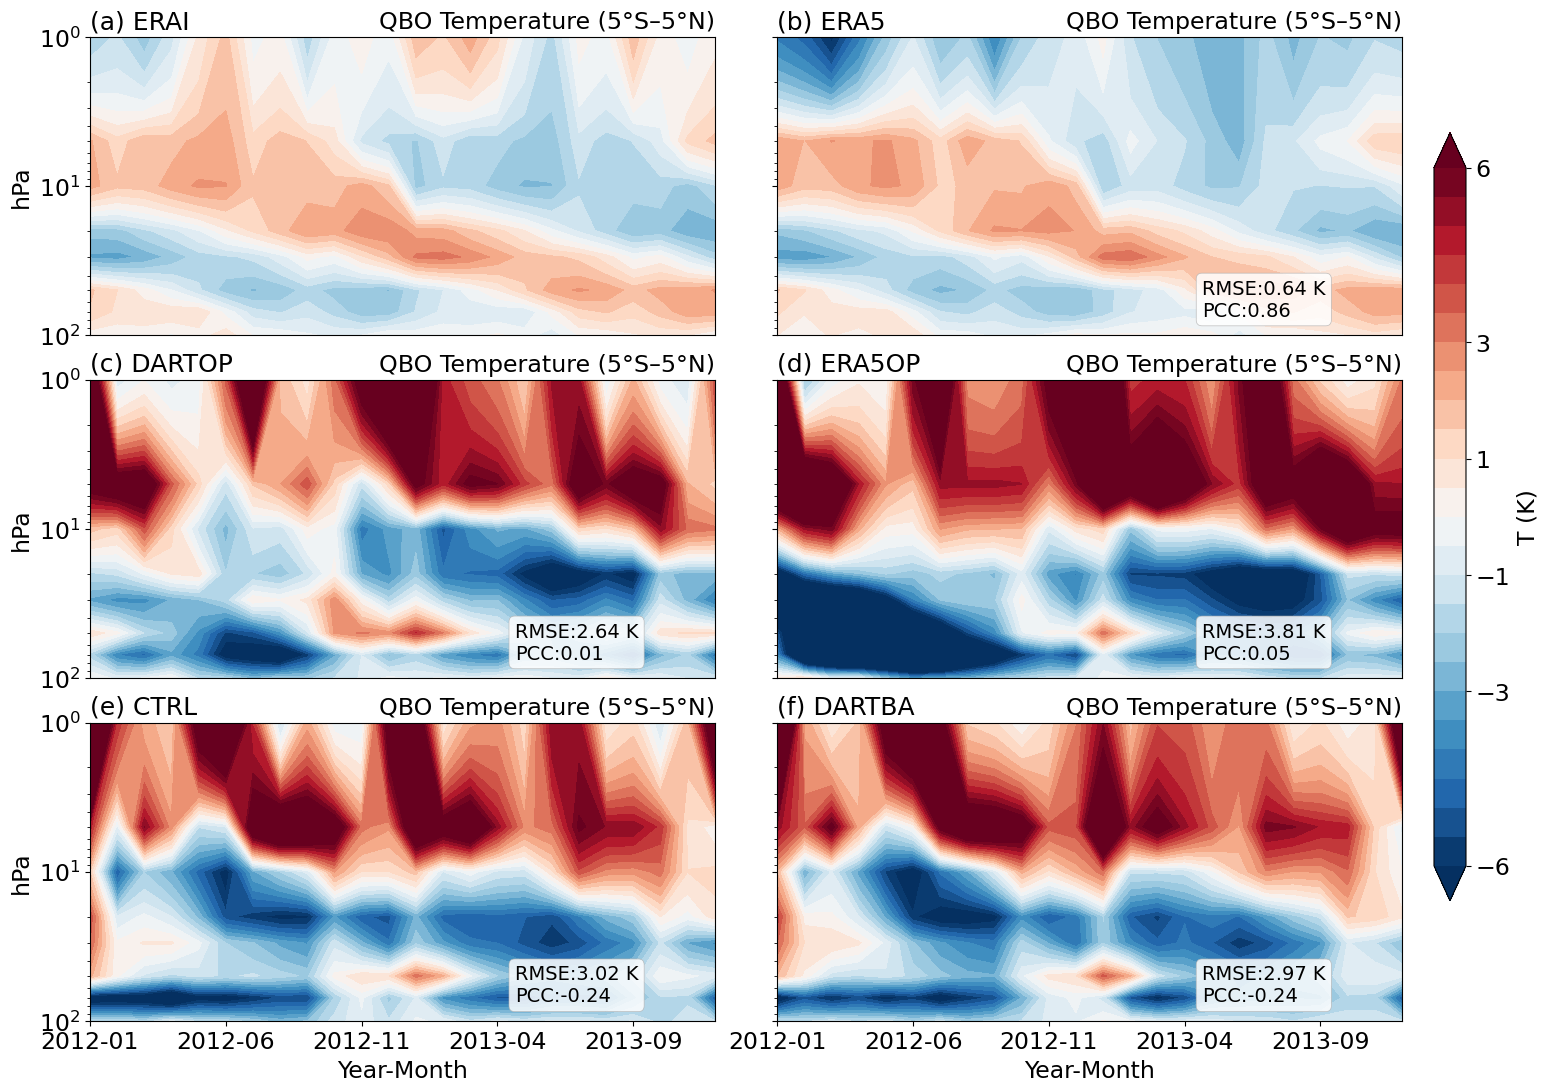

DONE


In [3]:
if __name__ == "__main__":
    work_dir = "/lcrc/group/e3sm/ac.szhang/acme_scratch/e3sm_project/v3_dart_paper"
    qbo_dir = Path(work_dir) / "figure_data" / "qbo"

    period = "2012-2013"
    ref_exp = "ERAI"
    exp_list = ["ERA5","DARTOP", "ERA5OP","CTRL", "DARTBA",] #, "ERA5DL", "ERA5BL", "DARTBL", "DARTBA", "DARTAE"]

    out_dir = Path(work_dir) / "qbo_analysis"
    out_dir.mkdir(parents=True, exist_ok=True)

    parameter = QboPlotParameter(
        main_title="QBO Temperature (5°S–5°N)",
        test_yrs=period,
        ref_yrs=f"{ref_exp} ({period})",
        var_label="T",
        var_units="K",
        default_field="qbo_anom",   # temperature: plot anomalies by default
    )
    plotter = QboPlotter(parameter)

    plotter.plot_timepressure_all_in_one(
        qbo_dir=qbo_dir,
        period=period,
        ref_exp=ref_exp,
        exp_list=exp_list,
        tag="ta",                   # temperature files use ta
        amplitude_method="rms",
        field=None,                 # uses parameter.default_field ("qbo_anom")
        output_dir=out_dir,
        nrows=3,
        ncols=2,
        skip_bad=True,
        font_scale=18,
        show=True,
        w_per_col=8,
        h_per_row=4,
        wspace=0.10,
        hspace=0.15,
        time_every=5,
    )
    print("DONE")
    

Wrote: /lcrc/group/e3sm/ac.szhang/acme_scratch/e3sm_project/v3_dart_paper/qbo_analysis/ua_qbo_raw_2012-2013_all_exps_plus_ERAI.png
Wrote: /lcrc/group/e3sm/ac.szhang/acme_scratch/e3sm_project/v3_dart_paper/qbo_analysis/ua_qbo_raw_2012-2013_all_exps_plus_ERAI.pdf


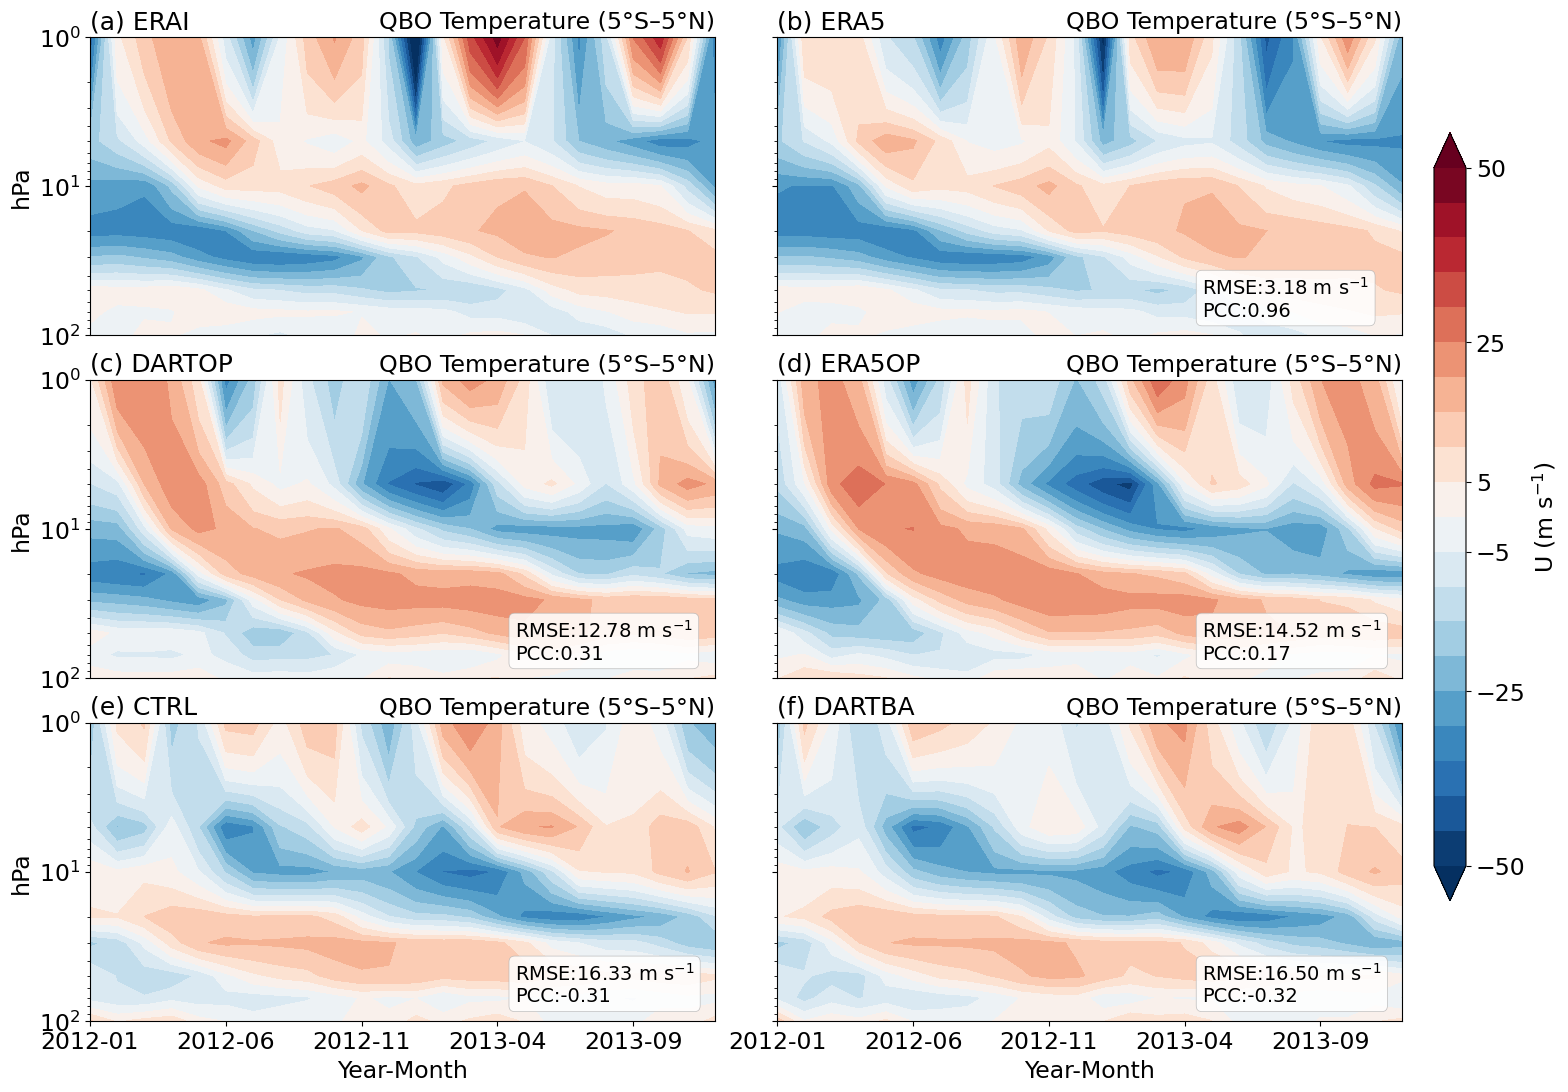

DONE


In [4]:
if __name__ == "__main__":
    work_dir = "/lcrc/group/e3sm/ac.szhang/acme_scratch/e3sm_project/v3_dart_paper"
    qbo_dir = Path(work_dir) / "figure_data" / "qbo"

    period = "2012-2013"
    ref_exp = "ERAI"
    exp_list = ["ERA5","DARTOP", "ERA5OP","CTRL", "DARTBA",] #, "ERA5DL", "ERA5BL", "DARTBL", "DARTBA", "DARTAE"]

    out_dir = Path(work_dir) / "qbo_analysis"
    out_dir.mkdir(parents=True, exist_ok=True)

    parameter = QboPlotParameter(
        main_title="QBO Temperature (5°S–5°N)",
        test_yrs=period,
        ref_yrs=f"{ref_exp} ({period})",
    )
    plotter = QboPlotter(parameter)

    # Example: 3x3 for 9 panels (ERA5 + 8 exps)
    plotter.plot_timepressure_all_in_one(
        qbo_dir=qbo_dir,
        period=period,
        ref_exp=ref_exp,
        exp_list=exp_list,
        amplitude_method="rms",
        output_dir=out_dir,
        nrows=3,
        ncols=2,
        skip_bad=True,
        font_scale=18, 
        show=True,
        w_per_col = 8,
        h_per_row = 4,
        wspace=0.10,
        hspace=0.15,
        time_every=5,
    )
    print("DONE")
    

In [ ]:
if __name__ == "__main__":
    work_dir = "/lcrc/group/e3sm/ac.szhang/acme_scratch/e3sm_project/v3_dart_paper"
    qbo_dir = Path(work_dir) / "figure_data" / "qbo"

    period = "2012-2013"
    ref_exp = "ERAI"
    exp_list = ["ERA5","DARTOP", "ERA5OP","CTRL", "DARTBA",] #, "ERA5DL", "ERA5BL", "DARTBL", "DARTBA", "DARTAE"]

    out_dir = Path(work_dir) / "qbo_analysis"
    out_dir.mkdir(parents=True, exist_ok=True)

    parameter = QboPlotParameter(
        main_title="QBO wind (5°S–5°N)",
        test_yrs=period,
        ref_yrs=f"{ref_exp} ({period})",
    )
    plotter = QboPlotter(parameter)
    
    # Example: diffs (8 panels) -> 3x3 still OK (last panel blank)
    plotter.plot_timepressure_diffs_all_in_one(
        qbo_dir=qbo_dir,
        period=period,
        ref_exp=ref_exp,
        exp_list=exp_list,
        amplitude_method="rms",
        output_dir=out_dir,
        nrows=3,
        ncols=2,
        skip_bad=True,
        show=True,
        w_per_col = 8,
        h_per_row = 4,
        font_scale=18, 
        wspace=0.10,
        hspace=0.15,
        time_every=5,
    )
    
    print("DONE")